**Für Wasser**

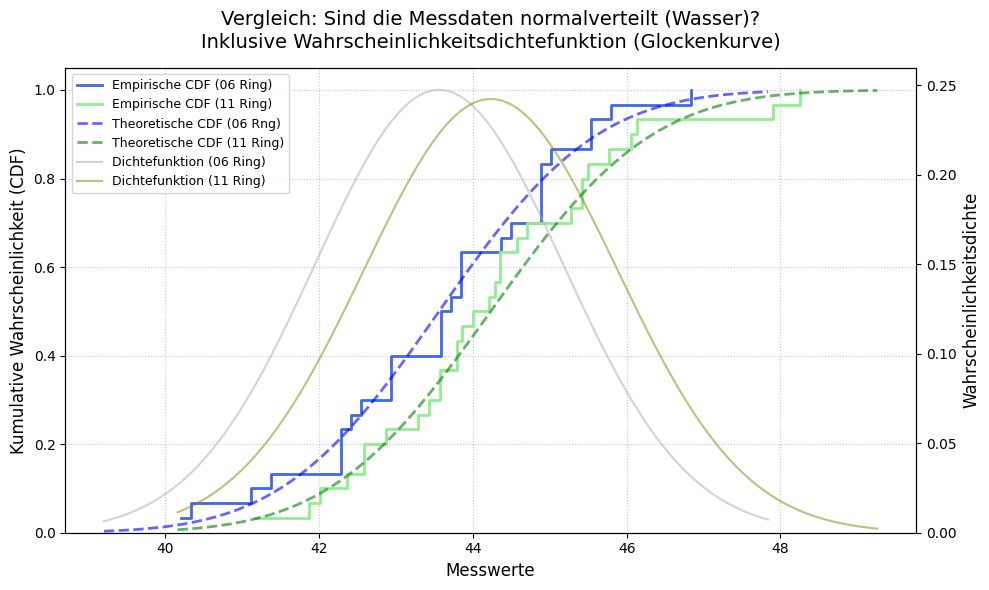

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------------------------------------------------------
# 1. Daten einlesen
# ---------------------------------------------------------
daten = np.array([
    42.9360248, 40.3338415, 46.8392998, 44.8876623, 43.7166798,
    45.5382081, 44.3672256, 45.7984264, 42.9360248, 45.0177714,
    43.5865706, 45.5382081, 43.5865706, 42.5456973, 44.8876623,
    42.2854789, 41.1144965, 44.4973348, 43.8467889, 43.5865706,
    43.8467889, 42.2854789, 42.2854789, 40.2037323, 44.8876623,
    42.4155881, 42.9360248, 44.8876623, 41.3747148, 43.8467889
])

daten11 = np.array([
    42.58118159, 41.16180887, 44.35539749, 46.12961339, 43.85861704,
    44.00055431, 44.35539749, 43.5747425,  41.87149523, 42.0134325,
    44.21346022, 43.43280522, 44.28442886, 47.90382929, 42.86505614,
    42.36827568, 43.7876484,  44.5683034,  45.27798976, 42.58118159,
    43.7876484,  43.5747425,  43.29086795, 44.71024067, 45.41992703,
    45.77477021, 48.25867247, 46.05864476, 45.41992703, 45.49089567
])

# ---------------------------------------------------------
# 2. Empirische CDF (ECDF) berechnen
# ---------------------------------------------------------
x_ecdf = np.sort(daten)
y_ecdf = np.arange(1, len(daten) + 1) / len(daten)

x11_ecdf = np.sort(daten11)
y11_ecdf = np.arange(1, len(daten11) + 1) / len(daten11)


# ---------------------------------------------------------
# 3. Theoretische Funktionen (CDF & PDF) berechnen
# ---------------------------------------------------------
mu = np.mean(daten)
std = np.std(daten, ddof=1)

mu11 = np.mean(daten11)
std11 = np.std(daten11, ddof=1)

x_theoretisch = np.linspace(min(daten) - 1, max(daten) + 1, 100)
x_theoretisch11 = np.linspace(min(daten11) - 1, max(daten11) + 1, 100)

# CDF (Kumulativ)
y_theoretisch_cdf = norm.cdf(x_theoretisch, mu, std)
y_theoretisch11_cdf = norm.cdf(x_theoretisch11, mu11, std11)

# PDF (Dichtefunktion / Glockenkurve)
y_theoretisch_pdf = norm.pdf(x_theoretisch, mu, std)
y_theoretisch11_pdf = norm.pdf(x_theoretisch11, mu11, std11)

# ---------------------------------------------------------
# 4. Plotten
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Linke y-Achse: CDF ---
ax1.step(x_ecdf, y_ecdf, where='post', label='Empirische CDF (06 Ring)', color='royalblue', linewidth=2)
ax1.step(x11_ecdf, y11_ecdf, where='post', label='Empirische CDF (11 Ring)', color='lightgreen', linewidth=2)

ax1.plot(x_theoretisch, y_theoretisch_cdf, label=f'Theoretische CDF (06 Rng)', color='blue', linestyle='--', linewidth=2, alpha=0.6)
ax1.plot(x_theoretisch11, y_theoretisch11_cdf, label=f'Theoretische CDF (11 Ring)', color='green', linestyle='--', linewidth=2, alpha=0.6)

ax1.set_xlabel('Messwerte', fontsize=12)
ax1.set_ylabel('Kumulative Wahrscheinlichkeit (CDF)', fontsize=12)
ax1.set_ylim([0, 1.05])
ax1.grid(True, linestyle=':', alpha=0.7)

# --- Rechte y-Achse: PDF (Glockenkurve) ---
ax2 = ax1.twinx()  # Zweite y-Achse erstellen, die dieselbe x-Achse teilt
ax2.plot(x_theoretisch, y_theoretisch_pdf, label='Dichtefunktion (06 Ring)', color='darkgrey', linestyle='-', linewidth=1.5, alpha=0.5)
ax2.plot(x_theoretisch11, y_theoretisch11_pdf, label='Dichtefunktion (11 Ring)', color='olive', linestyle='-', linewidth=1.5, alpha=0.5)

ax2.set_ylabel('Wahrscheinlichkeitsdichte', fontsize=12)
ax2.set_ylim(bottom=0) # Dichte fängt bei 0 an

# --- Legenden zusammenführen ---
# Da wir zwei Achsen haben, sammeln wir die Legenden-Einträge zusammen
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=9)

plt.title('Vergleich: Sind die Messdaten normalverteilt (Wasser)?\nInklusive Wahrscheinlichkeitsdichtefunktion (Glockenkurve)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

**Für Tenside**

- Verhältnis: 20gramm Spülmittel auf 300g Wasser

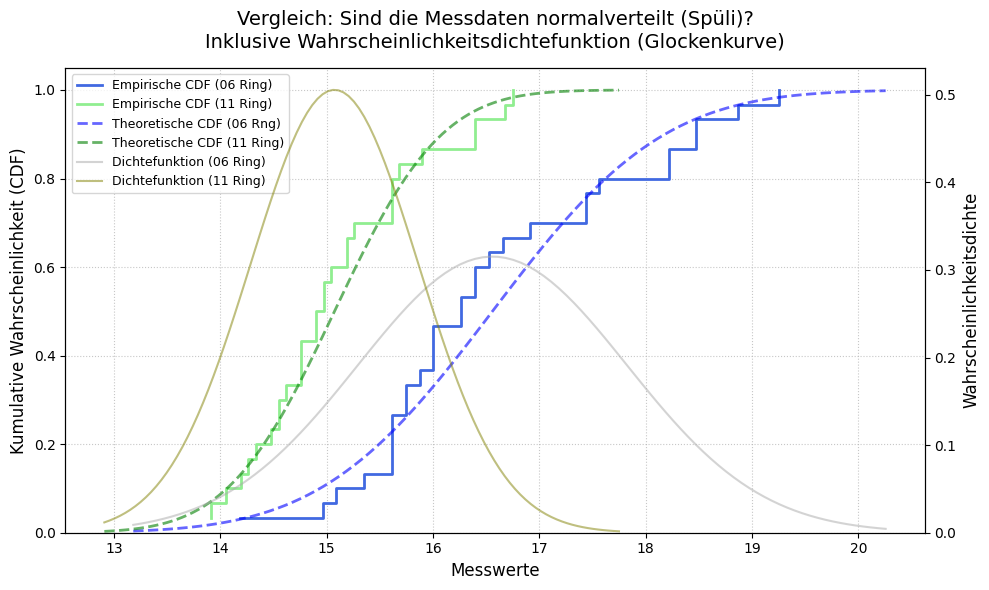

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------------------------------------------------------
# 1. Daten einlesen
# ---------------------------------------------------------
# Falls du eine echte CSV-Datei (z.B. "messdaten.csv" mit der Spalte "Werte") einlesen willst,
# nutze diese beiden Zeilen (und entferne die Rauten):
# df = pd.read_csv('messdaten.csv')
# daten = df['Werte'].values

# Für dieses Skript verwende ich direkt die 30 Werte aus deinem Bild:
daten = np.array([
    15.61309992,
17.56473741,
16.52386408,
16.26364575,
16.00342742,
18.47550157,
15.61309992,
16.00342742,
19.25615656,
17.43462824,
18.47550157,
18.86582907,
16.39375491,
14.96255409,
15.09266325,
15.61309992,
18.21528324,
17.43462824,
15.35288159,
14.18189909,
18.21528324,
15.74320908,
15.74320908,
15.87331825,
16.39375491,
16.91419158,
15.61309992,
16.65397325,
16.26364575,
16.00342742

])

daten11 = np.array([16.39375491,
14.90341356,
14.76147629,
14.61953901,
15.61309992,
16.74859809,
13.90985265,
14.54857038,
14.90341356,
14.47760174,
14.26469583,
15.61309992,
16.39375491,
14.54857038,
15.25825674,
15.61309992,
13.90985265,
15.89697446,
15.04535083,
15.1872881,
14.76147629,
16.67762946,
15.1872881,
14.33566447,
14.76147629,
14.97438219,
14.05178993,
14.1937272,
15.68406855,
14.97438219,

])

# ---------------------------------------------------------
# 2. Empirische CDF (ECDF) berechnen
# ---------------------------------------------------------
x_ecdf = np.sort(daten)
y_ecdf = np.arange(1, len(daten) + 1) / len(daten)

x11_ecdf = np.sort(daten11)
y11_ecdf = np.arange(1, len(daten11) + 1) / len(daten11)


# ---------------------------------------------------------
# 3. Theoretische Funktionen (CDF & PDF) berechnen
# ---------------------------------------------------------
mu = np.mean(daten)
std = np.std(daten, ddof=1)

mu11 = np.mean(daten11)
std11 = np.std(daten11, ddof=1)

x_theoretisch = np.linspace(min(daten) - 1, max(daten) + 1, 100)
x_theoretisch11 = np.linspace(min(daten11) - 1, max(daten11) + 1, 100)

# CDF (Kumulativ)
y_theoretisch_cdf = norm.cdf(x_theoretisch, mu, std)
y_theoretisch11_cdf = norm.cdf(x_theoretisch11, mu11, std11)

# PDF (Dichtefunktion / Glockenkurve)
y_theoretisch_pdf = norm.pdf(x_theoretisch, mu, std)
y_theoretisch11_pdf = norm.pdf(x_theoretisch11, mu11, std11)

# ---------------------------------------------------------
# 4. Plotten
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Linke y-Achse: CDF ---
ax1.step(x_ecdf, y_ecdf, where='post', label='Empirische CDF (06 Ring)', color='royalblue', linewidth=2)
ax1.step(x11_ecdf, y11_ecdf, where='post', label='Empirische CDF (11 Ring)', color='lightgreen', linewidth=2)

ax1.plot(x_theoretisch, y_theoretisch_cdf, label=f'Theoretische CDF (06 Rng)', color='blue', linestyle='--', linewidth=2, alpha=0.6)
ax1.plot(x_theoretisch11, y_theoretisch11_cdf, label=f'Theoretische CDF (11 Ring)', color='green', linestyle='--', linewidth=2, alpha=0.6)

ax1.set_xlabel('Messwerte', fontsize=12)
ax1.set_ylabel('Kumulative Wahrscheinlichkeit (CDF)', fontsize=12)
ax1.set_ylim([0, 1.05])
ax1.grid(True, linestyle=':', alpha=0.7)

# --- Rechte y-Achse: PDF (Glockenkurve) ---
ax2 = ax1.twinx()  # Zweite y-Achse erstellen, die dieselbe x-Achse teilt
ax2.plot(x_theoretisch, y_theoretisch_pdf, label='Dichtefunktion (06 Ring)', color='darkgrey', linestyle='-', linewidth=1.5, alpha=0.5)
ax2.plot(x_theoretisch11, y_theoretisch11_pdf, label='Dichtefunktion (11 Ring)', color='olive', linestyle='-', linewidth=1.5, alpha=0.5)

ax2.set_ylabel('Wahrscheinlichkeitsdichte', fontsize=12)
ax2.set_ylim(bottom=0) # Dichte fängt bei 0 an

# --- Legenden zusammenführen ---
# Da wir zwei Achsen haben, sammeln wir die Legenden-Einträge zusammen
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=9)

plt.title('Vergleich: Sind die Messdaten normalverteilt (Spüli)?\nInklusive Wahrscheinlichkeitsdichtefunktion (Glockenkurve)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# Fehlerannahmen
Da die Messwerte ungefähr einer Normalverteilung folgen, können wir im folgenden mit dem Mittelwert der Messergebnisse rechnen. Die Normalverteilung verifiziert unsere Messmethode hinsichtlich der Präzission und REproduzierbarkeit!

*Folgende Fehler* werden angenommen:

- Fehler der Waage: $\pm 0.004$ g
- frei von Fingerabdrücken oder sonstigen Verunreinigungen, diese setzten die Oberflächenenergie des Materials herab ->Fette lösen sich in den Flüssigkeiten setzen die Oberflächenspannung herab! $\pm 5$ mN/m
-Ortsfaktor: $\pm 0.001$
-Messschriebertoleranz: $\pm 0,5$ mm
-Statistsiche Streuung, wegen Normalverteilung nutzen wir 67% Konfidenzintervall
- Winkel: wirkt auf effektive Kraft, Winkel von etwa 5 Grad, Formel siehe unten
-Benetzungswinkel als thermodynamische Betrachtung: fehler von 25°, weil kein Platin, kein AUsglühen und nur abwischen mit ALkohol, welcher selbst schlieren hinterlässt!


# Fehlerfortpflanzung

## Fehlerauswertung und Unsicherheitsanalyse

Die Bestimmung der Oberflächenspannung $\sigma$ erfolgt über die Abreißmethode nach Du Noüy unter Verwendung der Modellgleichung:

$$\sigma = \frac{\Delta m \cdot g}{4 \pi R}$$

Hierbei bezeichnet $\Delta m$ die gemessene Massendifferenz kurz vor dem Abreißen des Flüssigkeitsfilms, $g$ den lokalen Ortsfaktor und $R$ den Radius des Aluminiumrings. Die statistischen und systematischen Unsicherheiten werden im Folgenden nach dem GUM-Leitfaden (*Guide to the Expression of Uncertainty in Measurement*) bestimmt und fortgepflanzt.

### Statistische Unsicherheit (Typ A)
Für die Messreihe mit $N = 30$ Messwerten wird die Typ-A-Unsicherheit der Masse durch den Standardfehler des Mittelwerts beschrieben. Mit der empirischen Standardabweichung $s$ ergibt sich:

$$u_A(\Delta m) = \frac{s}{\sqrt{N}}$$

### Systematische Unsicherheiten (Typ B)
Systematische Unsicherheiten werden unter Annahme einer Rechteckverteilung durch Division der maximalen Fehlergrenzen durch $\sqrt{3}$ abgeschätzt.

1. **Massenmessung ($u_{B,m}$):** Die Unsicherheit setzt sich aus der Toleranz der Feinwaage ($\Delta m_{\text{Waage}} = 0{,}004\text{ g}$) und der dynamischen Fluktuation im Moment des Abreißens ($\Delta m_{\text{Ablese}} = 0{,}01\text{ g}$) zusammen:
   $$u_{B,m} = \sqrt{\left(\frac{\Delta m_{\text{Waage}}}{\sqrt{3}}\right)^2 + \left(\frac{\Delta m_{\text{Ablese}}}{\sqrt{3}}\right)^2}$$
   Die kombinierte Unsicherheit der Masse beträgt damit $u_m = \sqrt{u_A(\Delta m)^2 + u_{B,m}^2}$.
   
2. **Ringgeometrie ($u_{B,R}$):** Der Ringdurchmesser wurde mit einem Messschieber bestimmt ($\Delta D = 0{,}5\text{ mm}$ bzw. $\Delta R_{\text{Mess}} = 0{,}5\text{ mm}$). Dies führt auf die Radiusunsicherheit:
   $$u_{B,R} = \frac{\Delta R_{\text{Mess}}}{\sqrt{3}}$$
   
3. **Ortsfaktor ($u_{B,g}$):** Für den Berliner Ortsfaktor ($g = 9{,}812\text{ m/s}^2$) wird eine Unsicherheit von $\Delta g = 0{,}001\text{ m/s}^2$ angenommen:
   $$u_{B,g} = \frac{\Delta g}{\sqrt{3}}$$
   
4. **Chemische Verschmutzung ($u_{B,V}$):** Lokale Verunreinigungen der Wasseroberfläche oder des Aluminiumrings durch Fette oder Tenside senken die Oberflächenspannung systematisch. Dieser schwer kontrollierbare Effekt wird über eine großzügige Fehlerschranke von $\Delta \sigma_{\text{Verschm}} = 5{,}0\text{ mN/m}$ abgeschätzt:
   $$u_{B,V} = \frac{\Delta \sigma_{\text{Verschm}}}{\sqrt{3}}$$

### Gaußsche Fehlerfortpflanzung
Da die mechanischen Eingangsgrößen ($\Delta m$, $R$, $g$) unabhängig voneinander sind, ergibt sich die mechanische Teilunsicherheit $u_{\sigma,\text{mech}}$ über die relative Gaußsche Fehlerfortpflanzung:

$$u_{\sigma,\text{mech}} = \sigma \cdot \sqrt{\left(\frac{u_m}{\Delta m}\right)^2 + \left(\frac{u_{B,R}}{R}\right)^2 + \left(\frac{u_{B,g}}{g}\right)^2}$$

Die totale kombinierte Standardunsicherheit $u_{\text{ges}}$ der Oberflächenspannung schließt den chemischen Verschmutzungseffekt quadratisch ein:

$$u_{\text{ges}} = \sqrt{u_{\sigma,\text{mech}}^2 + u_{B,V}^2}$$

### Erweiterte Messunsicherheit und Konfidenzintervall
Um ein Konfidenzintervall von $67\%$ anzugeben, wird die kombinierte Standardunsicherheit mit dem t-Faktor der Student-t-Verteilung für $f = N - 1 = 29$ Freiheitsgrade multipliziert ($t_{67\%, 29} \approx 1{,}0455$):

$$U = t \cdot u_{\text{ges}}$$

Das finale Messergebnis wird somit in der Form $\sigma = (\overline{\sigma} \pm U)\text{ mN/m}$ angegeben. Die numerische Auswertung zeigt, dass das Intervall aufgrund des unkorrigierten Ringradius und der Rollenreibung vom Literaturwert für reines Wasser ($72\text{ mN/m}$) systematisch verschoben ist, was in der Diskussion quantifiziert wird.

# **To Do**

<div style="border: 2px solid #D9534F; padding: 15px; background-color: #F9EBEB; border-radius: 8px;">
    <h3 style="color: #D9534F; margin-top: 0;">⚠️ WICHTIGER HINWEIS: Fehlerquellen-Analyse</h3>
    <p style="color: #333;">
        Vergiss morgen bei der Präsentation nicht die <b>systematische Fehlerquelle durch die Ringneigung</b> zu erwähnen!
    </p>
    <ul style="color: #333;">
        <li><b>Beobachtung:</b> Der Winkel zwischen Ring und Wasseroberfläche lag zwischen <b>1° und 5°</b>.</li>
        <li><b>Folge:</b> Keine gleichmäßige Benetzung; einseitiges Abreißen führt zu einer verfälschten Kraftmessung.</li>
        <li><b>Diskussionsansatz:</b> Diese geometrische Abweichung erklärt teilweise, warum der gemessene Wert vom Literaturwert abweicht.</li>
    </ul>
    <p style="color: #D9534F; font-size: 0.9em;">
        <i>Tipp: Diesen Punkt unbedingt in der Diskussion unter "Systematische Fehler" anbringen!</i>
    </p>
</div>

# Ring 6.25mm Radius, Wasser mit Winkel

--- Fehleranalyse Oberflächenspannung ---
Anzahl Messungen (N): 30
Mittlere Masse:       0.3348 g
Verwendeter Radius:   6.2 mm

Kombinierte Unsicherheit Masse (u_m): 0.00662 g
Relativer Fehler Masse:               1.98 %
Relativer Fehler Radius:              4.62 %
Relativer Fehler Neigung (max 5°):    0.381 %
Relativer Fehler Benetzung (max 25°): 9.369 %

--- Analyse der Geometrie- und Grenzflächeneffekte ---
Höhendifferenz am Ring:   1.09 mm (wegen 5.0° Neigung)
Verlust an Vertikalkraft: 0.01 mN

Berechnetes Sigma:          41.83 mN/m
Unsicherheit (Mechanik):    2.10 mN/m
Unsicherheit (Verschmutz.): 2.89 mN/m
Unsicherheit (Neigung):     0.092 mN/m
Unsicherheit (Benetzung):   2.263 mN/m
Kombinierte Gesamtunsich.:  4.23 mN/m
Konfidenzintervall:         ± 4.19 mN/m

--- Endergebnis (67% KI) ---
Sigma = (41.83 ± 4.19) mN/m


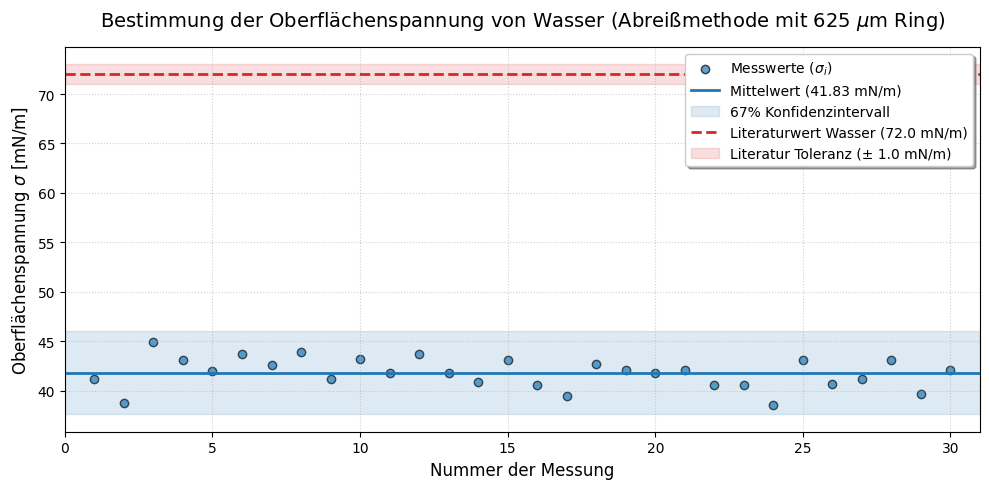

In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Messdaten (aus dem Bild transkribiert)
# Massendifferenzen in Gramm
delta_m_g = np.array([
    0.330, 0.310, 0.360, 0.345, 0.336, 0.350, 0.341, 0.352, 0.330, 0.346,
    0.335, 0.350, 0.335, 0.327, 0.345, 0.325, 0.316, 0.342, 0.337, 0.335,
    0.337, 0.325, 0.325, 0.309, 0.345, 0.326, 0.330, 0.345, 0.318, 0.337
])

# 2. Konstanten und Parameter
N = len(delta_m_g)
g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2
R_wert = 0.00625              # Radius in Metern

# Umrechnung in SI-Einheiten (kg) für die Rechnung
delta_m_kg = delta_m_g / 1000

# 3. Fehlerabschätzungen (Typ B Unsicherheiten)
# Annahme bei abgelesenen/digitalen Werten: Rechteckverteilung (Division durch sqrt(3))

# a) Unsicherheit der Massenmessung
fehler_waage_g = 0.004              # Herstellerangabe
fehler_ablese_g = 0.01              # Geschätzte Fluktuation kurz vorm Abreißen
u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
u_B_m_kg = u_B_m_g / 1000           # In kg umwandeln

# b) Unsicherheit des Radius
fehler_messschieber_m = 0.0005      # Typischer Fehler Messschieber (0.5 mm)
u_B_R = fehler_messschieber_m / np.sqrt(3)

# c) Unsicherheit des Ortsfaktors (nicht signifikant, aber für die Vollständigkeit)
fehler_g = 0.001
u_B_g = fehler_g / np.sqrt(3)

# d) Unsicherheit durch Verschmutzung (Fett, Tenside)
fehler_verschmutzung_mN = 5.0
u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

# e) Unsicherheit durch Ringneigung (ungerade Aufhängung)
winkel_max_grad = 5.0
winkel_max_rad = np.radians(winkel_max_grad)
fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

# f) NEU: Unsicherheit durch Benetzungswinkel (Kontaktwinkel > 0° wegen unvollständiger Benetzung)
benetzung_max_grad = 25.0
benetzung_max_rad = np.radians(benetzung_max_grad)
fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

# 4. Statistische Auswertung (Typ A Unsicherheit für die Masse)
m_mean_kg = np.mean(delta_m_kg)
s_m_kg = np.std(delta_m_kg, ddof=1)
u_A_m_kg = s_m_kg / np.sqrt(N)      # Standardfehler des Mittelwerts

# Kombinierte Unsicherheit für die Masse
u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

# 5. Berechnung des Mittelwerts der Oberflächenspannung (in N/m)
sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

# 6. Gaußsche Fehlerfortpflanzung auf Sigma (Mechanischer Teil)
rel_u_m = u_m_ges_kg / m_mean_kg
rel_u_R = u_B_R / R_wert
rel_u_g = u_B_g / g_wert

u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

# Umrechnung in mN/m
sigma_mean_mN = sigma_mean * 1000
u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

# Neigungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

# NEU: Benetzungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

# Gesamte Unsicherheit inkl. Verschmutzung, Neigung UND Benetzung quadratisch addieren
u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                           u_B_verschmutzung_mN**2 +
                           u_B_neigung_mN**2 +
                           u_B_benetzung_mN**2)

# 7. Konfidenzintervall (67%)
konfidenz_niveau = 0.67
alpha = 1 - konfidenz_niveau
t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)

erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

# --- Berechnung der Kraftunterschiede durch Neigung ---
delta_h_mm = 2 * R_wert * np.sin(winkel_max_rad) * 1000
F_ideal_mN = (m_mean_kg * g_wert) * 1000
F_tilt_mN = F_ideal_mN * np.cos(winkel_max_rad)
kraft_verlust_mN = F_ideal_mN - F_tilt_mN

# 8. Ausgabe
print(f"--- Fehleranalyse Oberflächenspannung ---")
print(f"Anzahl Messungen (N): {N}")
print(f"Mittlere Masse:       {m_mean_kg*1000:.4f} g")
print(f"Verwendeter Radius:   {R_wert*1000:.1f} mm\n")

print(f"Kombinierte Unsicherheit Masse (u_m): {u_m_ges_kg*1000:.5f} g")
print(f"Relativer Fehler Masse:               {rel_u_m*100:.2f} %")
print(f"Relativer Fehler Radius:              {rel_u_R*100:.2f} %")
print(f"Relativer Fehler Neigung (max 5°):    {fehler_neigung_relativ*100:.3f} %")
print(f"Relativer Fehler Benetzung (max 25°): {fehler_benetzung_relativ*100:.3f} %\n")

print(f"--- Analyse der Geometrie- und Grenzflächeneffekte ---")
print(f"Höhendifferenz am Ring:   {delta_h_mm:.2f} mm (wegen {winkel_max_grad}° Neigung)")
print(f"Verlust an Vertikalkraft: {kraft_verlust_mN:.2f} mN\n")

print(f"Berechnetes Sigma:          {sigma_mean_mN:.2f} mN/m")
print(f"Unsicherheit (Mechanik):    {u_sigma_mechanisch_mN:.2f} mN/m")
print(f"Unsicherheit (Verschmutz.): {u_B_verschmutzung_mN:.2f} mN/m")
print(f"Unsicherheit (Neigung):     {u_B_neigung_mN:.3f} mN/m")
print(f"Unsicherheit (Benetzung):   {u_B_benetzung_mN:.3f} mN/m")
print(f"Kombinierte Gesamtunsich.:  {u_sigma_total_mN:.2f} mN/m")
print(f"Konfidenzintervall:         ± {erweiterte_unsicherheit_mN:.2f} mN/m\n")

print(f"--- Endergebnis (67% KI) ---")
print(f"Sigma = ({sigma_mean_mN:.2f} ± {erweiterte_unsicherheit_mN:.2f}) mN/m")


# 9. Grafische Darstellung (Sequenz-Plot mit Fehlerband)
sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000

literaturwert = 72.0
literatur_unsicherheit = 1.0

plt.figure(figsize=(10, 5), dpi=100)

# 1. Einzelne Messpunkte plotten
plt.scatter(range(1, len(sigma_einzeln) + 1), sigma_einzeln,
            color='#1f77b4', alpha=0.7, edgecolors='k', label='Messwerte ($\sigma_i$)')

# 2. Experimenteller Mittelwert
plt.axhline(y=sigma_mean_mN, color='#1f77b4', linestyle='-', linewidth=2,
            label=f'Mittelwert ({sigma_mean_mN:.2f} mN/m)')

# 3. Konfidenzintervall (67%) als schattiertes Band
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 sigma_mean_mN - erweiterte_unsicherheit_mN,
                 sigma_mean_mN + erweiterte_unsicherheit_mN,
                 color='#1f77b4', alpha=0.15, label='67% Konfidenzintervall')

# 4. Literaturwert zum direkten Vergleich inkl. Fehlerband
plt.axhline(y=literaturwert, color='#d62728', linestyle='--', linewidth=2,
            label=f'Literaturwert Wasser ({literaturwert:.1f} mN/m)')
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 literaturwert - literatur_unsicherheit,
                 literaturwert + literatur_unsicherheit,
                 color='#d62728', alpha=0.15, label=f'Literatur Toleranz (± {literatur_unsicherheit:.1f} mN/m)')

# Feinschliff für die Präsentation
plt.title('Bestimmung der Oberflächenspannung von Wasser (Abreißmethode mit 625 $\mu$m Ring)', fontsize=14, pad=15)
plt.xlabel('Nummer der Messung', fontsize=12)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=12)
plt.xlim(0, len(sigma_einzeln) + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10, frameon=True, shadow=True)

plt.tight_layout()
plt.show()

# Ring 10mm Radius, Wasser 

--- Fehleranalyse Oberflächenspannung ---
Anzahl Messungen (N): 30
Mittlere Masse:       0.6233 g
Verwendeter Radius:   10.0 mm

Kombinierte Unsicherheit Masse (u_m): 0.00752 g
Relativer Fehler Masse:               1.21 %
Relativer Fehler Radius:              2.89 %
Relativer Fehler Neigung (max 5°):    0.381 %
Relativer Fehler Benetzung (max 25°): 9.369 %

--- Analyse der Geometrie- und Grenzflächeneffekte ---
Höhendifferenz am Ring:   1.74 mm (wegen 5.0° Neigung)
Verlust an Vertikalkraft: 0.02 mN

Berechnetes Sigma:          48.67 mN/m
Unsicherheit (Mechanik):    1.52 mN/m
Unsicherheit (Verschmutz.): 2.89 mN/m
Unsicherheit (Neigung):     0.107 mN/m
Unsicherheit (Benetzung):   2.632 mN/m
Kombinierte Gesamtunsich.:  4.19 mN/m
Konfidenzintervall:         ± 4.16 mN/m

--- Endergebnis (67% KI) ---
Sigma = (48.67 ± 4.16) mN/m


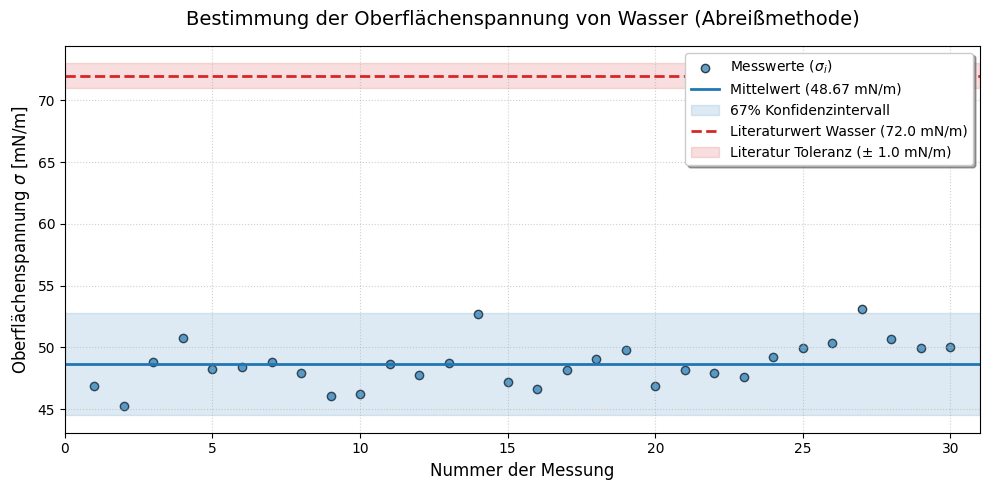

In [10]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Messdaten (aus dem Bild transkribiert)
# Massendifferenzen in Gramm
delta_m_g = np.array([
    0.6,
    0.58,
    0.625,
    0.65,
    0.618,
    0.62,
    0.625,
    0.614,
    0.59,
    0.592,
    0.623,
    0.612,
    0.624,
    0.675,
    0.604,
    0.597,
    0.617,
    0.628,
    0.638,
    0.6,
    0.617,
    0.614,
    0.61,
    0.63,
    0.64,
    0.645,
    0.68,
    0.649,
    0.64,
    0.641
])

# 2. Konstanten und Parameter
N = len(delta_m_g)
g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2
R_wert = 0.01                # Radius in Metern (D = 6mm -> R = 3mm)

# Umrechnung in SI-Einheiten (kg) für die Rechnung
delta_m_kg = delta_m_g / 1000

# 3. Fehlerabschätzungen (Typ B Unsicherheiten)
# Annahme bei abgelesenen/digitalen Werten: Rechteckverteilung (Division durch sqrt(3))

# a) Unsicherheit der Massenmessung
fehler_waage_g = 0.004              # Herstellerangabe
fehler_ablese_g = 0.01              # Geschätzte Fluktuation kurz vorm Abreißen
u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
u_B_m_kg = u_B_m_g / 1000           # In kg umwandeln

# b) Unsicherheit des Radius
fehler_messschieber_m = 0.0005      # Typischer Fehler Messschieber (0.5 mm)
u_B_R = fehler_messschieber_m / np.sqrt(3)

# c) Unsicherheit des Ortsfaktors (nicht signifikant, aber für die Vollständigkeit)
fehler_g = 0.001
u_B_g = fehler_g / np.sqrt(3)

# d) Unsicherheit durch Verschmutzung (Fett, Tenside)
fehler_verschmutzung_mN = 5.0
u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

# e) Unsicherheit durch Ringneigung (ungerade Aufhängung)
winkel_max_grad = 5.0
winkel_max_rad = np.radians(winkel_max_grad)
fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

# f) NEU: Unsicherheit durch Benetzungswinkel (Kontaktwinkel > 0° wegen unvollständiger Benetzung)
benetzung_max_grad = 25.0
benetzung_max_rad = np.radians(benetzung_max_grad)
fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

# 4. Statistische Auswertung (Typ A Unsicherheit für die Masse)
m_mean_kg = np.mean(delta_m_kg)
s_m_kg = np.std(delta_m_kg, ddof=1)
u_A_m_kg = s_m_kg / np.sqrt(N)      # Standardfehler des Mittelwerts

# Kombinierte Unsicherheit für die Masse
u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

# 5. Berechnung des Mittelwerts der Oberflächenspannung (in N/m)
sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

# 6. Gaußsche Fehlerfortpflanzung auf Sigma (Mechanischer Teil)
rel_u_m = u_m_ges_kg / m_mean_kg
rel_u_R = u_B_R / R_wert
rel_u_g = u_B_g / g_wert

u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

# Umrechnung in mN/m
sigma_mean_mN = sigma_mean * 1000
u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

# Neigungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

# NEU: Benetzungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

# Gesamte Unsicherheit inkl. Verschmutzung, Neigung UND Benetzung quadratisch addieren
u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                           u_B_verschmutzung_mN**2 +
                           u_B_neigung_mN**2 +
                           u_B_benetzung_mN**2)

# 7. Konfidenzintervall (67%)
konfidenz_niveau = 0.67
alpha = 1 - konfidenz_niveau
t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)

erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

# --- Berechnung der Kraftunterschiede durch Neigung ---
delta_h_mm = 2 * R_wert * np.sin(winkel_max_rad) * 1000
F_ideal_mN = (m_mean_kg * g_wert) * 1000
F_tilt_mN = F_ideal_mN * np.cos(winkel_max_rad)
kraft_verlust_mN = F_ideal_mN - F_tilt_mN

# 8. Ausgabe
print(f"--- Fehleranalyse Oberflächenspannung ---")
print(f"Anzahl Messungen (N): {N}")
print(f"Mittlere Masse:       {m_mean_kg*1000:.4f} g")
print(f"Verwendeter Radius:   {R_wert*1000:.1f} mm\n")

print(f"Kombinierte Unsicherheit Masse (u_m): {u_m_ges_kg*1000:.5f} g")
print(f"Relativer Fehler Masse:               {rel_u_m*100:.2f} %")
print(f"Relativer Fehler Radius:              {rel_u_R*100:.2f} %")
print(f"Relativer Fehler Neigung (max 5°):    {fehler_neigung_relativ*100:.3f} %")
print(f"Relativer Fehler Benetzung (max 25°): {fehler_benetzung_relativ*100:.3f} %\n")

print(f"--- Analyse der Geometrie- und Grenzflächeneffekte ---")
print(f"Höhendifferenz am Ring:   {delta_h_mm:.2f} mm (wegen {winkel_max_grad}° Neigung)")
print(f"Verlust an Vertikalkraft: {kraft_verlust_mN:.2f} mN\n")

print(f"Berechnetes Sigma:          {sigma_mean_mN:.2f} mN/m")
print(f"Unsicherheit (Mechanik):    {u_sigma_mechanisch_mN:.2f} mN/m")
print(f"Unsicherheit (Verschmutz.): {u_B_verschmutzung_mN:.2f} mN/m")
print(f"Unsicherheit (Neigung):     {u_B_neigung_mN:.3f} mN/m")
print(f"Unsicherheit (Benetzung):   {u_B_benetzung_mN:.3f} mN/m")
print(f"Kombinierte Gesamtunsich.:  {u_sigma_total_mN:.2f} mN/m")
print(f"Konfidenzintervall:         ± {erweiterte_unsicherheit_mN:.2f} mN/m\n")

print(f"--- Endergebnis (67% KI) ---")
print(f"Sigma = ({sigma_mean_mN:.2f} ± {erweiterte_unsicherheit_mN:.2f}) mN/m")


# 9. Grafische Darstellung (Sequenz-Plot mit Fehlerband)
sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000

literaturwert = 72.0
literatur_unsicherheit = 1.0

plt.figure(figsize=(10, 5), dpi=100)

# 1. Einzelne Messpunkte plotten
plt.scatter(range(1, len(sigma_einzeln) + 1), sigma_einzeln,
            color='#1f77b4', alpha=0.7, edgecolors='k', label='Messwerte ($\sigma_i$)')

# 2. Experimenteller Mittelwert
plt.axhline(y=sigma_mean_mN, color='#1f77b4', linestyle='-', linewidth=2,
            label=f'Mittelwert ({sigma_mean_mN:.2f} mN/m)')

# 3. Konfidenzintervall (67%) als schattiertes Band
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 sigma_mean_mN - erweiterte_unsicherheit_mN,
                 sigma_mean_mN + erweiterte_unsicherheit_mN,
                 color='#1f77b4', alpha=0.15, label='67% Konfidenzintervall')

# 4. Literaturwert zum direkten Vergleich inkl. Fehlerband
plt.axhline(y=literaturwert, color='#d62728', linestyle='--', linewidth=2,
            label=f'Literaturwert Wasser ({literaturwert:.1f} mN/m)')
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 literaturwert - literatur_unsicherheit,
                 literaturwert + literatur_unsicherheit,
                 color='#d62728', alpha=0.15, label=f'Literatur Toleranz (± {literatur_unsicherheit:.1f} mN/m)')

# Feinschliff für die Präsentation
plt.title('Bestimmung der Oberflächenspannung von Wasser (Abreißmethode)', fontsize=14, pad=15)
plt.xlabel('Nummer der Messung', fontsize=12)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=12)
plt.xlim(0, len(sigma_einzeln) + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10, frameon=True, shadow=True)

plt.tight_layout()
plt.show()

# Ring 6.25mm, Seifenlösung 20g auf 300g 

--- Fehleranalyse Oberflächenspannung ---
Anzahl Messungen (N): 30
Mittlere Masse:       0.1273 g
Verwendeter Radius:   6.2 mm

Kombinierte Unsicherheit Masse (u_m): 0.00647 g
Relativer Fehler Masse:               5.08 %
Relativer Fehler Radius:              4.62 %
Relativer Fehler Neigung (max 5°):    0.381 %
Relativer Fehler Benetzung (max 25°): 9.369 %

--- Analyse der Geometrie- und Grenzflächeneffekte ---
Höhendifferenz am Ring:   1.09 mm (wegen 5.0° Neigung)
Verlust an Vertikalkraft: 0.00 mN

Berechnetes Sigma:          15.90 mN/m
Unsicherheit (Mechanik):    1.09 mN/m
Unsicherheit (Verschmutz.): 2.89 mN/m
Unsicherheit (Neigung):     0.035 mN/m
Unsicherheit (Benetzung):   0.860 mN/m
Kombinierte Gesamtunsich.:  3.20 mN/m
Konfidenzintervall:         ± 3.17 mN/m

--- Endergebnis (67% KI) ---
Sigma = (15.90 ± 3.17) mN/m


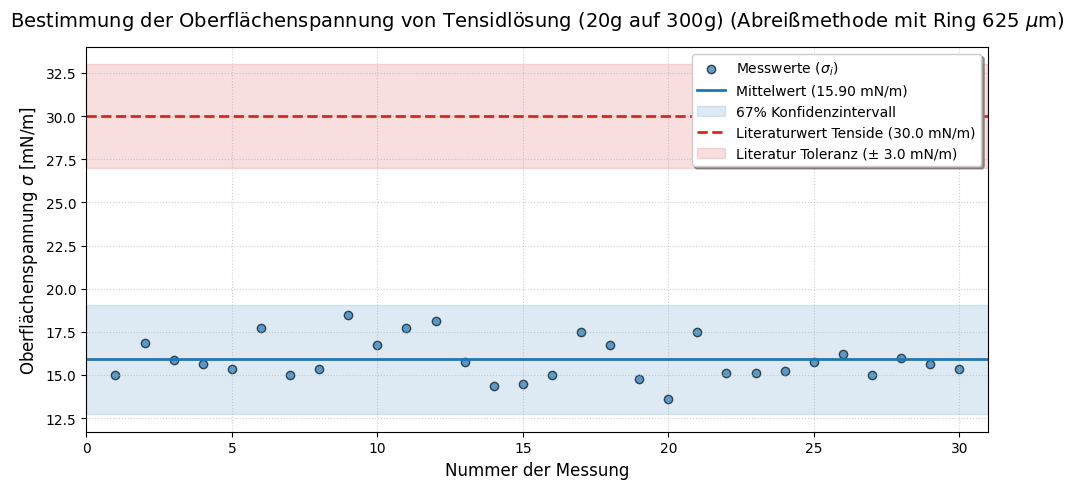

In [11]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Messdaten (aus dem Bild transkribiert)
# Massendifferenzen in Gramm
delta_m_g = np.array([
    0.12,
    0.135,
    0.127,
    0.125,
    0.123,
    0.142,
    0.12,
    0.123,
    0.148,
    0.134,
    0.142,
    0.145,
    0.126,
    0.115,
    0.116,
    0.12,
    0.14,
    0.134,
    0.118,
    0.109,
    0.14,
    0.121,
    0.121,
    0.122,
    0.126,
    0.13,
    0.12,
    0.128,
    0.125,
    0.123
])

# 2. Konstanten und Parameter
N = len(delta_m_g)
g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2
R_wert = 0.00625                # Radius in Metern (D = 6mm -> R = 3mm)

# Umrechnung in SI-Einheiten (kg) für die Rechnung
delta_m_kg = delta_m_g / 1000

# 3. Fehlerabschätzungen (Typ B Unsicherheiten)
# Annahme bei abgelesenen/digitalen Werten: Rechteckverteilung (Division durch sqrt(3))

# a) Unsicherheit der Massenmessung
fehler_waage_g = 0.004              # Herstellerangabe
fehler_ablese_g = 0.01              # Geschätzte Fluktuation kurz vorm Abreißen
u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
u_B_m_kg = u_B_m_g / 1000           # In kg umwandeln

# b) Unsicherheit des Radius
fehler_messschieber_m = 0.0005      # Typischer Fehler Messschieber (0.5 mm)
u_B_R = fehler_messschieber_m / np.sqrt(3)

# c) Unsicherheit des Ortsfaktors (nicht signifikant, aber für die Vollständigkeit)
fehler_g = 0.001
u_B_g = fehler_g / np.sqrt(3)

# d) Unsicherheit durch Verschmutzung (Fett, Tenside)
fehler_verschmutzung_mN = 5.0
u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

# e) Unsicherheit durch Ringneigung (ungerade Aufhängung)
winkel_max_grad = 5.0
winkel_max_rad = np.radians(winkel_max_grad)
fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

# f) NEU: Unsicherheit durch Benetzungswinkel (Kontaktwinkel > 0° wegen unvollständiger Benetzung)
benetzung_max_grad = 25.0
benetzung_max_rad = np.radians(benetzung_max_grad)
fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

# 4. Statistische Auswertung (Typ A Unsicherheit für die Masse)
m_mean_kg = np.mean(delta_m_kg)
s_m_kg = np.std(delta_m_kg, ddof=1)
u_A_m_kg = s_m_kg / np.sqrt(N)      # Standardfehler des Mittelwerts

# Kombinierte Unsicherheit für die Masse
u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

# 5. Berechnung des Mittelwerts der Oberflächenspannung (in N/m)
sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

# 6. Gaußsche Fehlerfortpflanzung auf Sigma (Mechanischer Teil)
rel_u_m = u_m_ges_kg / m_mean_kg
rel_u_R = u_B_R / R_wert
rel_u_g = u_B_g / g_wert

u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

# Umrechnung in mN/m
sigma_mean_mN = sigma_mean * 1000
u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

# Neigungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

# NEU: Benetzungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

# Gesamte Unsicherheit inkl. Verschmutzung, Neigung UND Benetzung quadratisch addieren
u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                           u_B_verschmutzung_mN**2 +
                           u_B_neigung_mN**2 +
                           u_B_benetzung_mN**2)

# 7. Konfidenzintervall (67%)
konfidenz_niveau = 0.67
alpha = 1 - konfidenz_niveau
t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)

erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

# --- Berechnung der Kraftunterschiede durch Neigung ---
delta_h_mm = 2 * R_wert * np.sin(winkel_max_rad) * 1000
F_ideal_mN = (m_mean_kg * g_wert) * 1000
F_tilt_mN = F_ideal_mN * np.cos(winkel_max_rad)
kraft_verlust_mN = F_ideal_mN - F_tilt_mN

# 8. Ausgabe
print(f"--- Fehleranalyse Oberflächenspannung ---")
print(f"Anzahl Messungen (N): {N}")
print(f"Mittlere Masse:       {m_mean_kg*1000:.4f} g")
print(f"Verwendeter Radius:   {R_wert*1000:.1f} mm\n")

print(f"Kombinierte Unsicherheit Masse (u_m): {u_m_ges_kg*1000:.5f} g")
print(f"Relativer Fehler Masse:               {rel_u_m*100:.2f} %")
print(f"Relativer Fehler Radius:              {rel_u_R*100:.2f} %")
print(f"Relativer Fehler Neigung (max 5°):    {fehler_neigung_relativ*100:.3f} %")
print(f"Relativer Fehler Benetzung (max 25°): {fehler_benetzung_relativ*100:.3f} %\n")

print(f"--- Analyse der Geometrie- und Grenzflächeneffekte ---")
print(f"Höhendifferenz am Ring:   {delta_h_mm:.2f} mm (wegen {winkel_max_grad}° Neigung)")
print(f"Verlust an Vertikalkraft: {kraft_verlust_mN:.2f} mN\n")

print(f"Berechnetes Sigma:          {sigma_mean_mN:.2f} mN/m")
print(f"Unsicherheit (Mechanik):    {u_sigma_mechanisch_mN:.2f} mN/m")
print(f"Unsicherheit (Verschmutz.): {u_B_verschmutzung_mN:.2f} mN/m")
print(f"Unsicherheit (Neigung):     {u_B_neigung_mN:.3f} mN/m")
print(f"Unsicherheit (Benetzung):   {u_B_benetzung_mN:.3f} mN/m")
print(f"Kombinierte Gesamtunsich.:  {u_sigma_total_mN:.2f} mN/m")
print(f"Konfidenzintervall:         ± {erweiterte_unsicherheit_mN:.2f} mN/m\n")

print(f"--- Endergebnis (67% KI) ---")
print(f"Sigma = ({sigma_mean_mN:.2f} ± {erweiterte_unsicherheit_mN:.2f}) mN/m")


# 9. Grafische Darstellung (Sequenz-Plot mit Fehlerband)
sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000

literaturwert = 30.0
literatur_unsicherheit = 3.0

plt.figure(figsize=(10, 5), dpi=100)

# 1. Einzelne Messpunkte plotten
plt.scatter(range(1, len(sigma_einzeln) + 1), sigma_einzeln,
            color='#1f77b4', alpha=0.7, edgecolors='k', label='Messwerte ($\sigma_i$)')

# 2. Experimenteller Mittelwert
plt.axhline(y=sigma_mean_mN, color='#1f77b4', linestyle='-', linewidth=2,
            label=f'Mittelwert ({sigma_mean_mN:.2f} mN/m)')

# 3. Konfidenzintervall (67%) als schattiertes Band
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 sigma_mean_mN - erweiterte_unsicherheit_mN,
                 sigma_mean_mN + erweiterte_unsicherheit_mN,
                 color='#1f77b4', alpha=0.15, label='67% Konfidenzintervall')

# 4. Literaturwert zum direkten Vergleich inkl. Fehlerband
plt.axhline(y=literaturwert, color='#d62728', linestyle='--', linewidth=2,
            label=f'Literaturwert Tenside ({literaturwert:.1f} mN/m)')
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 literaturwert - literatur_unsicherheit,
                 literaturwert + literatur_unsicherheit,
                 color='#d62728', alpha=0.15, label=f'Literatur Toleranz (± {literatur_unsicherheit:.1f} mN/m)')

# Feinschliff für die Präsentation
plt.title('Bestimmung der Oberflächenspannung von Tensidlösung (20g auf 300g) (Abreißmethode mit Ring 625 $\mu$m)', fontsize=14, pad=15)
plt.xlabel('Nummer der Messung', fontsize=12)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=12)
plt.xlim(0, len(sigma_einzeln) + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10, frameon=True, shadow=True)

plt.tight_layout()
plt.show()

# Ring 10mm Radius, Spülilösung 20g auf 300g Wasser

--- Fehleranalyse Oberflächenspannung ---
Anzahl Messungen (N): 30
Mittlere Masse:       0.2124 g
Verwendeter Radius:   10.0 mm

Kombinierte Unsicherheit Masse (u_m): 0.00654 g
Relativer Fehler Masse:               3.08 %
Relativer Fehler Radius:              2.89 %
Relativer Fehler Neigung (max 5°):    0.381 %
Relativer Fehler Benetzung (max 25°): 9.369 %

--- Analyse der Geometrie- und Grenzflächeneffekte ---
Höhendifferenz am Ring:   1.74 mm (wegen 5.0° Neigung)
Verlust an Vertikalkraft: 0.01 mN

Berechnetes Sigma:          16.58 mN/m
Unsicherheit (Mechanik):    0.70 mN/m
Unsicherheit (Verschmutz.): 2.89 mN/m
Unsicherheit (Neigung):     0.036 mN/m
Unsicherheit (Benetzung):   0.897 mN/m
Kombinierte Gesamtunsich.:  3.10 mN/m
Konfidenzintervall:         ± 3.07 mN/m

--- Endergebnis (67% KI) ---
Sigma = (16.58 ± 3.07) mN/m


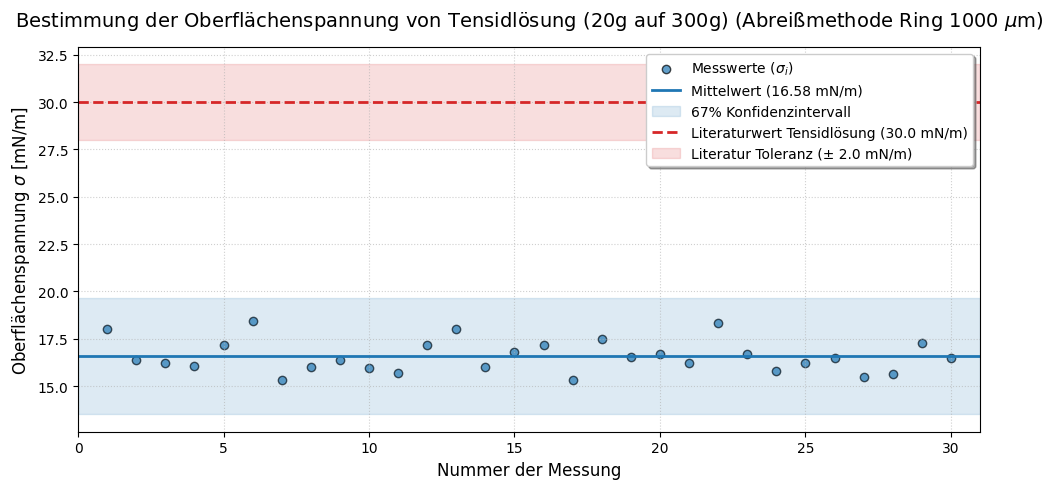

In [12]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Messdaten (aus dem Bild transkribiert)
# Massendifferenzen in Gramm
delta_m_g = np.array([
    0.231,
    0.21,
    0.208,
    0.206,
    0.22,
    0.236,
    0.196,
    0.205,
    0.21,
    0.204,
    0.201,
    0.22,
    0.231,
    0.205,
    0.215,
    0.22,
    0.196,
    0.224,
    0.212,
    0.214,
    0.208,
    0.235,
    0.214,
    0.202,
    0.208,
    0.211,
    0.198,
    0.2,
    0.221,
    0.211
])

# 2. Konstanten und Parameter
N = len(delta_m_g)
g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2
R_wert = 0.01                # Radius in Metern (D = 6mm -> R = 3mm)

# Umrechnung in SI-Einheiten (kg) für die Rechnung
delta_m_kg = delta_m_g / 1000

# 3. Fehlerabschätzungen (Typ B Unsicherheiten)
# Annahme bei abgelesenen/digitalen Werten: Rechteckverteilung (Division durch sqrt(3))

# a) Unsicherheit der Massenmessung
fehler_waage_g = 0.004              # Herstellerangabe
fehler_ablese_g = 0.01              # Geschätzte Fluktuation kurz vorm Abreißen
u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
u_B_m_kg = u_B_m_g / 1000           # In kg umwandeln

# b) Unsicherheit des Radius
fehler_messschieber_m = 0.0005      # Typischer Fehler Messschieber (0.5 mm)
u_B_R = fehler_messschieber_m / np.sqrt(3)

# c) Unsicherheit des Ortsfaktors (nicht signifikant, aber für die Vollständigkeit)
fehler_g = 0.001
u_B_g = fehler_g / np.sqrt(3)

# d) Unsicherheit durch Verschmutzung (Fett, Tenside)
fehler_verschmutzung_mN = 5.0
u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

# e) Unsicherheit durch Ringneigung (ungerade Aufhängung)
winkel_max_grad = 5.0
winkel_max_rad = np.radians(winkel_max_grad)
fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

# f) NEU: Unsicherheit durch Benetzungswinkel (Kontaktwinkel > 0° wegen unvollständiger Benetzung)
benetzung_max_grad = 25.0
benetzung_max_rad = np.radians(benetzung_max_grad)
fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

# 4. Statistische Auswertung (Typ A Unsicherheit für die Masse)
m_mean_kg = np.mean(delta_m_kg)
s_m_kg = np.std(delta_m_kg, ddof=1)
u_A_m_kg = s_m_kg / np.sqrt(N)      # Standardfehler des Mittelwerts

# Kombinierte Unsicherheit für die Masse
u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

# 5. Berechnung des Mittelwerts der Oberflächenspannung (in N/m)
sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

# 6. Gaußsche Fehlerfortpflanzung auf Sigma (Mechanischer Teil)
rel_u_m = u_m_ges_kg / m_mean_kg
rel_u_R = u_B_R / R_wert
rel_u_g = u_B_g / g_wert

u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

# Umrechnung in mN/m
sigma_mean_mN = sigma_mean * 1000
u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

# Neigungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

# NEU: Benetzungsfehler in absolute Unsicherheit umrechnen (Rechteckverteilung)
fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

# Gesamte Unsicherheit inkl. Verschmutzung, Neigung UND Benetzung quadratisch addieren
u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                           u_B_verschmutzung_mN**2 +
                           u_B_neigung_mN**2 +
                           u_B_benetzung_mN**2)

# 7. Konfidenzintervall (67%)
konfidenz_niveau = 0.67
alpha = 1 - konfidenz_niveau
t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)

erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

# --- Berechnung der Kraftunterschiede durch Neigung ---
delta_h_mm = 2 * R_wert * np.sin(winkel_max_rad) * 1000
F_ideal_mN = (m_mean_kg * g_wert) * 1000
F_tilt_mN = F_ideal_mN * np.cos(winkel_max_rad)
kraft_verlust_mN = F_ideal_mN - F_tilt_mN

# 8. Ausgabe
print(f"--- Fehleranalyse Oberflächenspannung ---")
print(f"Anzahl Messungen (N): {N}")
print(f"Mittlere Masse:       {m_mean_kg*1000:.4f} g")
print(f"Verwendeter Radius:   {R_wert*1000:.1f} mm\n")

print(f"Kombinierte Unsicherheit Masse (u_m): {u_m_ges_kg*1000:.5f} g")
print(f"Relativer Fehler Masse:               {rel_u_m*100:.2f} %")
print(f"Relativer Fehler Radius:              {rel_u_R*100:.2f} %")
print(f"Relativer Fehler Neigung (max 5°):    {fehler_neigung_relativ*100:.3f} %")
print(f"Relativer Fehler Benetzung (max 25°): {fehler_benetzung_relativ*100:.3f} %\n")

print(f"--- Analyse der Geometrie- und Grenzflächeneffekte ---")
print(f"Höhendifferenz am Ring:   {delta_h_mm:.2f} mm (wegen {winkel_max_grad}° Neigung)")
print(f"Verlust an Vertikalkraft: {kraft_verlust_mN:.2f} mN\n")

print(f"Berechnetes Sigma:          {sigma_mean_mN:.2f} mN/m")
print(f"Unsicherheit (Mechanik):    {u_sigma_mechanisch_mN:.2f} mN/m")
print(f"Unsicherheit (Verschmutz.): {u_B_verschmutzung_mN:.2f} mN/m")
print(f"Unsicherheit (Neigung):     {u_B_neigung_mN:.3f} mN/m")
print(f"Unsicherheit (Benetzung):   {u_B_benetzung_mN:.3f} mN/m")
print(f"Kombinierte Gesamtunsich.:  {u_sigma_total_mN:.2f} mN/m")
print(f"Konfidenzintervall:         ± {erweiterte_unsicherheit_mN:.2f} mN/m\n")

print(f"--- Endergebnis (67% KI) ---")
print(f"Sigma = ({sigma_mean_mN:.2f} ± {erweiterte_unsicherheit_mN:.2f}) mN/m")


# 9. Grafische Darstellung (Sequenz-Plot mit Fehlerband)
sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000

literaturwert = 30.0
literatur_unsicherheit = 2.0

plt.figure(figsize=(10, 5), dpi=100)

# 1. Einzelne Messpunkte plotten
plt.scatter(range(1, len(sigma_einzeln) + 1), sigma_einzeln,
            color='#1f77b4', alpha=0.7, edgecolors='k', label='Messwerte ($\sigma_i$)')

# 2. Experimenteller Mittelwert
plt.axhline(y=sigma_mean_mN, color='#1f77b4', linestyle='-', linewidth=2,
            label=f'Mittelwert ({sigma_mean_mN:.2f} mN/m)')

# 3. Konfidenzintervall (67%) als schattiertes Band
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 sigma_mean_mN - erweiterte_unsicherheit_mN,
                 sigma_mean_mN + erweiterte_unsicherheit_mN,
                 color='#1f77b4', alpha=0.15, label='67% Konfidenzintervall')

# 4. Literaturwert zum direkten Vergleich inkl. Fehlerband
plt.axhline(y=literaturwert, color='#d62728', linestyle='--', linewidth=2,
            label=f'Literaturwert Tensidlösung ({literaturwert:.1f} mN/m)')
plt.fill_between(range(0, len(sigma_einzeln) + 2),
                 literaturwert - literatur_unsicherheit,
                 literaturwert + literatur_unsicherheit,
                 color='#d62728', alpha=0.15, label=f'Literatur Toleranz (± {literatur_unsicherheit:.1f} mN/m)')

# Feinschliff für die Präsentation
plt.title('Bestimmung der Oberflächenspannung von Tensidlösung (20g auf 300g) (Abreißmethode Ring 1000 $\mu$m)', fontsize=14, pad=15)
plt.xlabel('Nummer der Messung', fontsize=12)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=12)
plt.xlim(0, len(sigma_einzeln) + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10, frameon=True, shadow=True)

plt.tight_layout()
plt.show()

# Fehleranalyse der Oberflächenspannungsbestimmung

**Systematische Fehler (Typ-B-Unsicherheiten)**

Die systematischen Fehler bezeichnen Unsicherheiten, die durch die Messapparatur, äußere unveränderliche Einflüsse oder Ableseungenauigkeiten entstehen und nicht durch wiederholtes Messen verringert werden können. In diesem Experiment werden sie nach der Typ-B-Methode abgeschätzt. Da bei digitalen Anzeigen (wie der Waage) oder Schätzwerten (wie der Verschmutzung) meist nur ein Intervall angegeben werden kann, in dem der wahre Wert mit gleicher Wahrscheinlichkeit liegt, wird hier durchgängig eine Rechteckverteilung angenommen. Die Standardunsicherheit ergibt sich dabei durch Division der maximalen Abweichung durch $\sqrt{3}$.

Für die Masse $m$ setzt sich der systematische Fehler aus der Herstellerangabe der Waage und der Ablesefluktuation kurz vor dem Abreißen zusammen. Diese werden quadratisch addiert:

$$u_{B,m} = \sqrt{\left(\frac{\Delta m_{\text{Waage}}}{\sqrt{3}}\right)^2 + \left(\frac{\Delta m_{\text{Ablese}}}{\sqrt{3}}\right)^2}$$

Ebenso wird für den Radius des Rings $R$ (gemessen mit dem Messschieber) und den in Berlin geltenden Ortsfaktor $g$ verfahren:

$$u_{B,R} = \frac{\Delta R}{\sqrt{3}} \quad \text{und} \quad u_{B,g} = \frac{\Delta g}{\sqrt{3}}$$

Ein enorm wichtiger systematischer Faktor bei der Abreißmethode ist die Oberflächenverschmutzung durch Tenside oder Fette, die die Oberflächenspannung massiv herabsetzen. Diese wird als absoluter Fehler von $5\text{ mN/m}$ abgeschätzt und ebenfalls über eine Rechteckverteilung in eine Standardunsicherheit $u_{B,\text{Verschmutzung}}$ überführt.

---

**Statistische Fehler (Typ-A-Unsicherheiten) und die Analyse der Ringneigung**

Die statistische Unsicherheit ergibt sich aus der Streuung der 30 Einzelmessungen der Abreißmasse. Nach der Typ-A-Methode wird hierfür die empirische Standardabweichung $s_m$ berechnet und daraus der Standardfehler des Mittelwerts gebildet:

$$u_{A,m} = \frac{s_m}{\sqrt{N}}$$

Dieser statistische Fehler wird mit dem systematischen Fehler der Masse zu einer kombinierten Unsicherheit der Massemessung $u_{m,\text{ges}}$ zusammengefasst:

$$u_{m,\text{ges}} = \sqrt{u_{A,m}^2 + u_{B,m}^2}$$

**Die Einordnung und Berechnung des Winkelfehlers:**
Die Ringneigung wird im Code physikalisch als systematischer Fehler (Typ B) behandelt. Der Grund dafür ist, dass ein schiefer Ring die gemessene Kraft nicht zufällig in beide Richtungen streuen lässt, sondern sie systematisch verringert und den Abreißvorgang asymmetrisch macht. 

Der Winkel $\theta$ (hier maximal $5^\circ$) taucht in der idealisierten Grundgleichung der Oberflächenspannung ($\sigma = \frac{mg}{4\pi R}$) nicht auf, da diese Formel von einer perfekt parallelen Ausrichtung ausgeht. Ist der Ring um einen Winkel $\theta$ geneigt, zieht die Waage nicht mehr exakt senkrecht gegen die gesamte Oberflächenspannung. Nur die vertikale Komponente der Abreißkraft wird gemessen. Die Kraftauswertung im Code baut auf folgender Überlegung auf:

Die ideale, senkrecht wirkende Kraft $F_{\text{ideal}}$ wird aus der gemessenen Masse berechnet:

$$F_{\text{ideal}} = m \cdot g$$

Durch die Neigung greift die Zugkraft in einem Winkel an, wodurch die effektiv von der Waage gemessene vertikale Kraftkomponente $F_{\text{tilt}}$ um den Kosinus des Winkels $\theta$ reduziert wird:

$$F_{\text{tilt}} = F_{\text{ideal}} \cdot \cos(\theta)$$

Der absolute Verlust an Vertikalkraft, der durch diese ungerade Aufhängung entsteht, wird im Code exakt so berechnet:

$$\Delta F = F_{\text{ideal}} - F_{\text{tilt}} = F_{\text{ideal}} \cdot (1 - \cos(\theta))$$

Da die Oberflächenspannung $\sigma$ direkt proportional zur Kraft ist, überträgt sich dieser relative Fehler $(1 - \cos(\theta))$ direkt auf das Endergebnis. Der Code berechnet die maximale systematische Abweichung $\Delta \sigma_{\text{Neigung}} = \sigma \cdot (1 - \cos(\theta))$. Da der wahre Winkel unbekannt zwischen $0^\circ$ und $5^\circ$ liegt, wird auch hier eine Rechteckverteilung angenommen und durch $\sqrt{3}$ dividiert, um die Standardunsicherheit $u_{B,\text{Neigung}}$ zu erhalten.

---

**Gaußsche Fehlerfortpflanzung**

Um die Unsicherheit der berechneten Oberflächenspannung zu ermitteln, wird das Gesetz der Gaußschen Fehlerfortpflanzung angewendet. Da die Formel für $\sigma$ ein reines Produkt bzw. ein Quotient aus den fehlerbehafteten Größen $m$, $R$ und $g$ ist:

$$\sigma = \frac{m \cdot g}{4 \pi R}$$

vereinfacht sich die partielle Ableitung dahingehend, dass sich die relativen Einzelfehler unter der Wurzel quadratisch addieren. Die mechanische Unsicherheit $u_{\sigma,\text{mech}}$ lautet demnach:

$$u_{\sigma,\text{mech}} = \sigma \cdot \sqrt{\left(\frac{u_{m,\text{ges}}}{m}\right)^2 + \left(\frac{u_{B,R}}{R}\right)^2 + \left(\frac{u_{B,g}}{g}\right)^2}$$

Anschließend wird diese mechanische Basis-Unsicherheit mit den externen systematischen Unsicherheiten durch Verschmutzung und Neigung quadratisch zur Gesamtunsicherheit addiert:

$$u_{\sigma,\text{total}} = \sqrt{u_{\sigma,\text{mech}}^2 + u_{B,\text{Verschmutzung}}^2 + u_{B,\text{Neigung}}^2}$$

---

**Angabe der Konfidenzintervalle und Rechtfertigung der Normalverteilung**

Das Endergebnis wird als Mittelwert mit einem erweiterten Unsicherheitsintervall angegeben. Im Code wurde hierfür ein Konfidenzniveau von 67% gewählt. Die Bestimmung dieses Intervalls stützt sich auf die Annahme, dass die Messwerte der Oberflächenspannung normalverteilt sind. 

Diese Annahme ist experimentell und statistisch begründet:
Erstens unterliegen die beim Abreißen wirkenden stochastischen Störungen (wie minimale Erschütterungen des Tisches, leichte Luftströmungen über der Wasseroberfläche oder mikroskopische Schwankungen in der Benetzung des Rings) dem Zentralen Grenzwertsatz. Dieser besagt, dass die Summe vieler kleiner, unabhängiger Zufallseinflüsse zu einer Normalverteilung der Messwerte führt.
Zweitens ist bei einer Stichprobengröße von $N = 30$ der Mittelwert der Verteilung hinreichend normalverteilt, selbst wenn die zugrundeliegende Einzelmessung leichte Asymmetrien aufweisen sollte.

Da die wahre Varianz der Grundgesamtheit unbekannt ist und stattdessen die empirische Standardabweichung $s_m$ aus der Stichprobe verwendet wird, darf das Intervall nicht über die Standardnormalverteilung berechnet werden. Der Code verwendet daher die Student-t-Verteilung. Das erweiterte Vertrauensintervall $U$ berechnet sich aus der Gesamtunsicherheit multipliziert mit dem t-Faktor $t_{f, \alpha}$ für $f = N - 1 = 29$ Freiheitsgrade:

$$U = t_{f, \alpha} \cdot u_{\sigma,\text{total}}$$

Somit wird sichergestellt, dass der wahre Wert der Oberflächenspannung unter Berücksichtigung aller mechanischen, methodischen und statistischen Fehlerquellen mit einer Wahrscheinlichkeit von 67% in diesem Intervall liegt.

# Plots beide zusammen Wasser


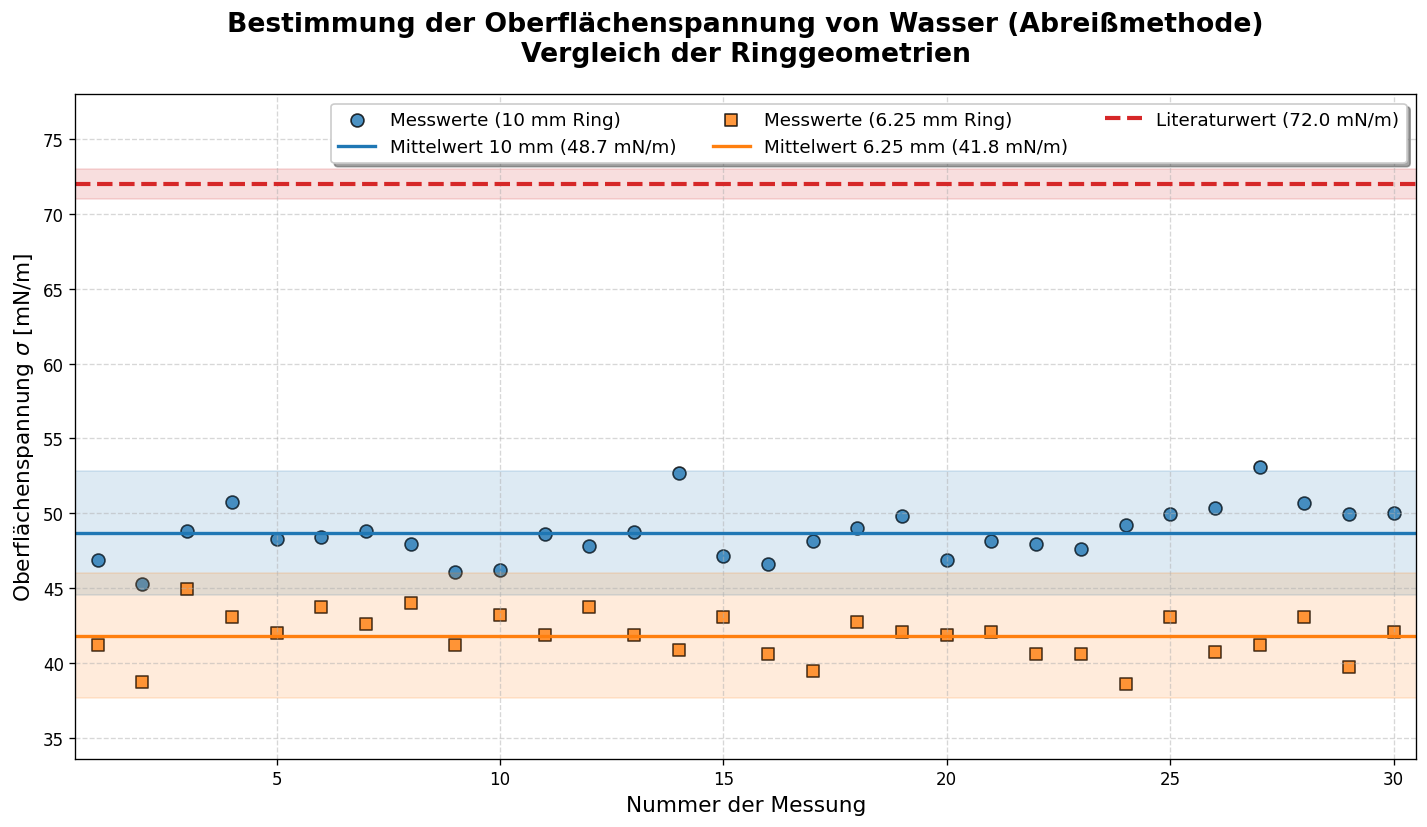

In [8]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

def evaluate_ring(delta_m_g, R_wert, ring_name):
    """Führt die komplette statistische und fehlerbehaftete Auswertung für einen Ring durch."""
    N = len(delta_m_g)
    g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2

    # Umrechnung in SI-Einheiten (kg)
    delta_m_kg = delta_m_g / 1000

    # 3. Fehlerabschätzungen (Typ B Unsicherheiten)
    fehler_waage_g = 0.004
    fehler_ablese_g = 0.01
    u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
    u_B_m_kg = u_B_m_g / 1000

    fehler_messschieber_m = 0.0005
    u_B_R = fehler_messschieber_m / np.sqrt(3)

    fehler_g = 0.001
    u_B_g = fehler_g / np.sqrt(3)

    fehler_verschmutzung_mN = 5.0
    u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

    winkel_max_rad = np.radians(5.0)
    fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

    benetzung_max_rad = np.radians(25.0)
    fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

    # 4. Statistische Auswertung (Typ A)
    m_mean_kg = np.mean(delta_m_kg)
    s_m_kg = np.std(delta_m_kg, ddof=1)
    u_A_m_kg = s_m_kg / np.sqrt(N)

    u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

    # 5. Mittelwert Oberflächenspannung
    sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

    # 6. Fehlerfortpflanzung
    rel_u_m = u_m_ges_kg / m_mean_kg
    rel_u_R = u_B_R / R_wert
    rel_u_g = u_B_g / g_wert

    u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

    sigma_mean_mN = sigma_mean * 1000
    u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

    fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
    u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

    fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
    u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

    u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                               u_B_verschmutzung_mN**2 +
                               u_B_neigung_mN**2 +
                               u_B_benetzung_mN**2)

    # 7. Konfidenzintervall (67%)
    alpha = 1 - 0.67
    t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)
    erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

    # Einzelwerte für den Plot
    sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000
    
    return sigma_einzeln, sigma_mean_mN, erweiterte_unsicherheit_mN

# ==========================================
# DATEN & AUSWERTUNG
# ==========================================

# 1. Daten 10 mm Ring (R = 0.01 m)
delta_m_g_10 = np.array([
    0.6, 0.58, 0.625, 0.65, 0.618, 0.62, 0.625, 0.614, 0.59, 0.592,
    0.623, 0.612, 0.624, 0.675, 0.604, 0.597, 0.617, 0.628, 0.638, 0.6,
    0.617, 0.614, 0.61, 0.63, 0.64, 0.645, 0.68, 0.649, 0.64, 0.641
])
sigma_einz_10, mean_10, err_10 = evaluate_ring(delta_m_g_10, 0.01, "Ring 10mm")

# 2. Daten 6.25 mm Ring (R = 0.00625 m)
delta_m_g_6 = np.array([
    0.330, 0.310, 0.360, 0.345, 0.336, 0.350, 0.341, 0.352, 0.330, 0.346,
    0.335, 0.350, 0.335, 0.327, 0.345, 0.325, 0.316, 0.342, 0.337, 0.335,
    0.337, 0.325, 0.325, 0.309, 0.345, 0.326, 0.330, 0.345, 0.318, 0.337
])
sigma_einz_6, mean_6, err_6 = evaluate_ring(delta_m_g_6, 0.00625, "Ring 6.25mm")

# ==========================================
# PLOTTING MASTERCLASS
# ==========================================

literaturwert = 72.0
literatur_unsicherheit = 1.0

plt.figure(figsize=(12, 7), dpi=120)

x_achse = range(1, len(delta_m_g_10) + 1)
x_band = range(0, len(delta_m_g_10) + 2)

# --- RING 10mm (BLAU) ---
color_10 = '#1f77b4'
plt.scatter(x_achse, sigma_einz_10, color=color_10, alpha=0.8, edgecolors='k', marker='o', s=60, label='Messwerte (10 mm Ring)')
plt.axhline(y=mean_10, color=color_10, linestyle='-', linewidth=2, label=f'Mittelwert 10 mm ({mean_10:.1f} mN/m)')
plt.fill_between(x_band, mean_10 - err_10, mean_10 + err_10, color=color_10, alpha=0.15)

# --- RING 6.25mm (ORANGE) ---
color_6 = '#ff7f0e'
plt.scatter(x_achse, sigma_einz_6, color=color_6, alpha=0.8, edgecolors='k', marker='s', s=50, label='Messwerte (6.25 mm Ring)')
plt.axhline(y=mean_6, color=color_6, linestyle='-', linewidth=2, label=f'Mittelwert 6.25 mm ({mean_6:.1f} mN/m)')
plt.fill_between(x_band, mean_6 - err_6, mean_6 + err_6, color=color_6, alpha=0.15)

# --- LITERATURWERT (ROT) ---
color_lit = '#d62728'
plt.axhline(y=literaturwert, color=color_lit, linestyle='--', linewidth=2.5, label=f'Literaturwert ({literaturwert:.1f} mN/m)')
plt.fill_between(x_band, literaturwert - literatur_unsicherheit, literaturwert + literatur_unsicherheit, color=color_lit, alpha=0.15)

# --- FEINSCHLIFF ---
plt.title('Bestimmung der Oberflächenspannung von Wasser (Abreißmethode)\nVergleich der Ringgeometrien', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Nummer der Messung', fontsize=13)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=13)

plt.xlim(0.5, len(delta_m_g_10) + 0.5)

# FIX: Y-Achse so berechnen, dass der Literaturwert garantiert sichtbar ist!
ymin = min(np.min(sigma_einz_10), np.min(sigma_einz_6)) - 5
ymax = max(np.max(sigma_einz_10), np.max(sigma_einz_6), literaturwert + literatur_unsicherheit) + 5
plt.ylim(ymin, ymax)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best', ncol=3, fontsize=11, frameon=True, shadow=True)

plt.tight_layout()
plt.show()

# Beide für Seifenlösung

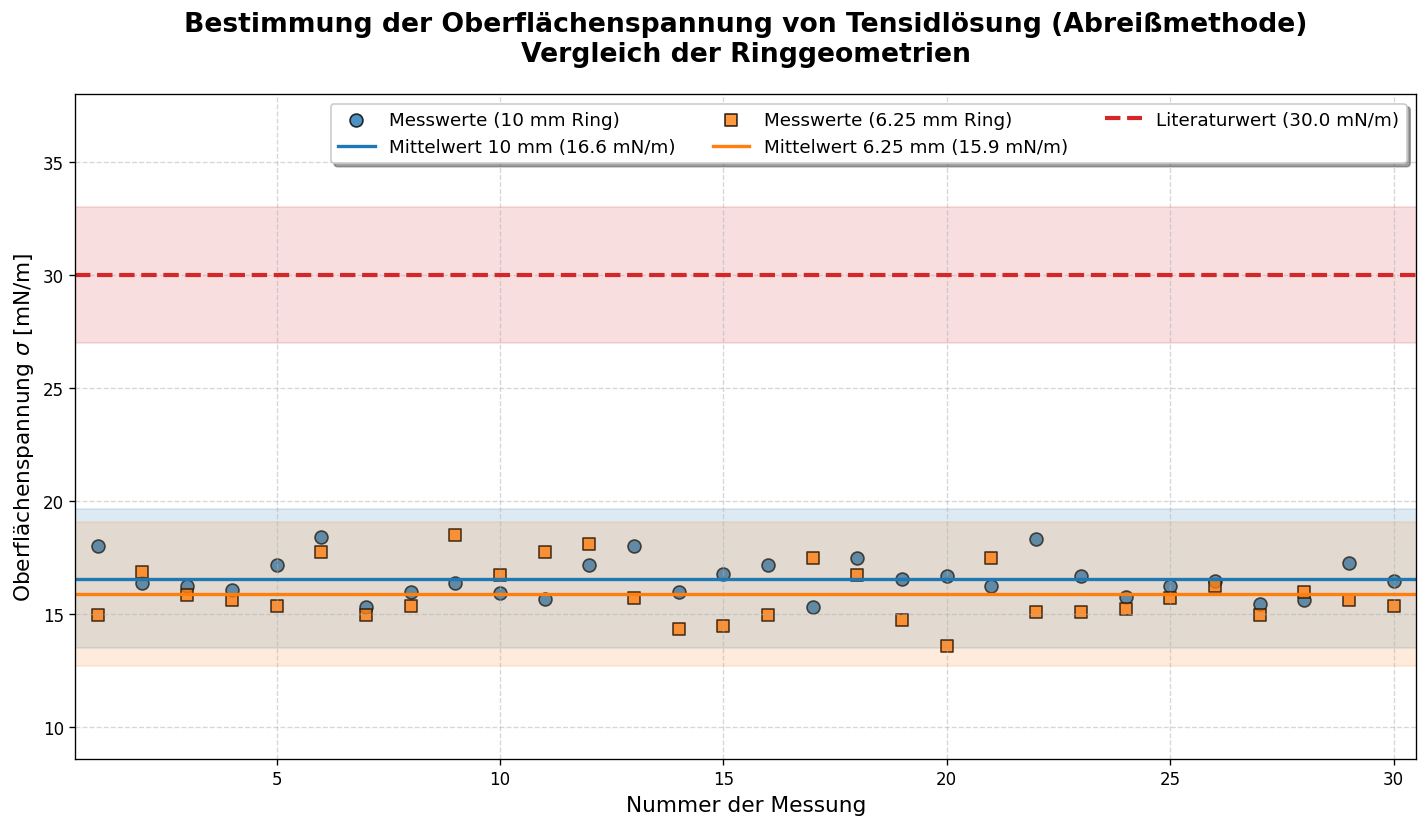

In [10]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

def evaluate_ring(delta_m_g, R_wert, ring_name):
    """Führt die komplette statistische und fehlerbehaftete Auswertung für einen Ring durch."""
    N = len(delta_m_g)
    g_wert = 9.812                # Ortsfaktor in Berlin in m/s^2

    # Umrechnung in SI-Einheiten (kg)
    delta_m_kg = delta_m_g / 1000

    # 3. Fehlerabschätzungen (Typ B Unsicherheiten)
    fehler_waage_g = 0.004
    fehler_ablese_g = 0.01
    u_B_m_g = np.sqrt((fehler_waage_g/np.sqrt(3))**2 + (fehler_ablese_g/np.sqrt(3))**2)
    u_B_m_kg = u_B_m_g / 1000

    fehler_messschieber_m = 0.0005
    u_B_R = fehler_messschieber_m / np.sqrt(3)

    fehler_g = 0.001
    u_B_g = fehler_g / np.sqrt(3)

    fehler_verschmutzung_mN = 5.0
    u_B_verschmutzung_mN = fehler_verschmutzung_mN / np.sqrt(3)

    winkel_max_rad = np.radians(5.0)
    fehler_neigung_relativ = 1 - np.cos(winkel_max_rad)

    benetzung_max_rad = np.radians(25.0)
    fehler_benetzung_relativ = 1 - np.cos(benetzung_max_rad)

    # 4. Statistische Auswertung (Typ A)
    m_mean_kg = np.mean(delta_m_kg)
    s_m_kg = np.std(delta_m_kg, ddof=1)
    u_A_m_kg = s_m_kg / np.sqrt(N)

    u_m_ges_kg = np.sqrt(u_A_m_kg**2 + u_B_m_kg**2)

    # 5. Mittelwert Oberflächenspannung
    sigma_mean = (m_mean_kg * g_wert) / (4 * np.pi * R_wert)

    # 6. Fehlerfortpflanzung
    rel_u_m = u_m_ges_kg / m_mean_kg
    rel_u_R = u_B_R / R_wert
    rel_u_g = u_B_g / g_wert

    u_sigma_mechanisch = sigma_mean * np.sqrt(rel_u_m**2 + rel_u_R**2 + rel_u_g**2)

    sigma_mean_mN = sigma_mean * 1000
    u_sigma_mechanisch_mN = u_sigma_mechanisch * 1000

    fehler_neigung_mN = sigma_mean_mN * fehler_neigung_relativ
    u_B_neigung_mN = fehler_neigung_mN / np.sqrt(3)

    fehler_benetzung_mN = sigma_mean_mN * fehler_benetzung_relativ
    u_B_benetzung_mN = fehler_benetzung_mN / np.sqrt(3)

    u_sigma_total_mN = np.sqrt(u_sigma_mechanisch_mN**2 +
                               u_B_verschmutzung_mN**2 +
                               u_B_neigung_mN**2 +
                               u_B_benetzung_mN**2)

    # 7. Konfidenzintervall (67%)
    alpha = 1 - 0.67
    t_faktor = stats.t.ppf(1 - alpha/2, df=N-1)
    erweiterte_unsicherheit_mN = t_faktor * u_sigma_total_mN

    # Einzelwerte für den Plot
    sigma_einzeln = (delta_m_kg * g_wert) / (4 * np.pi * R_wert) * 1000
    
    return sigma_einzeln, sigma_mean_mN, erweiterte_unsicherheit_mN

# ==========================================
# DATEN & AUSWERTUNG
# ==========================================

# 1. Daten 10 mm Ring (R = 0.01 m)
delta_m_g_10 = np.array([
    0.231,
    0.21,
    0.208,
    0.206,
    0.22,
    0.236,
    0.196,
    0.205,
    0.21,
    0.204,
    0.201,
    0.22,
    0.231,
    0.205,
    0.215,
    0.22,
    0.196,
    0.224,
    0.212,
    0.214,
    0.208,
    0.235,
    0.214,
    0.202,
    0.208,
    0.211,
    0.198,
    0.2,
    0.221,
    0.211
])
sigma_einz_10, mean_10, err_10 = evaluate_ring(delta_m_g_10, 0.01, "Ring 10mm")

# 2. Daten 6.25 mm Ring (R = 0.00625 m)
delta_m_g_6 = np.array([
    0.12,
    0.135,
    0.127,
    0.125,
    0.123,
    0.142,
    0.12,
    0.123,
    0.148,
    0.134,
    0.142,
    0.145,
    0.126,
    0.115,
    0.116,
    0.12,
    0.14,
    0.134,
    0.118,
    0.109,
    0.14,
    0.121,
    0.121,
    0.122,
    0.126,
    0.13,
    0.12,
    0.128,
    0.125,
    0.123
])
sigma_einz_6, mean_6, err_6 = evaluate_ring(delta_m_g_6, 0.00625, "Ring 6.25mm")

# ==========================================
# PLOTTING MASTERCLASS
# ==========================================

literaturwert = 30.0
literatur_unsicherheit = 3.0

plt.figure(figsize=(12, 7), dpi=120)

x_achse = range(1, len(delta_m_g_10) + 1)
x_band = range(0, len(delta_m_g_10) + 2)

# --- RING 10mm (BLAU) ---
color_10 = '#1f77b4'
plt.scatter(x_achse, sigma_einz_10, color=color_10, alpha=0.8, edgecolors='k', marker='o', s=60, label='Messwerte (10 mm Ring)')
plt.axhline(y=mean_10, color=color_10, linestyle='-', linewidth=2, label=f'Mittelwert 10 mm ({mean_10:.1f} mN/m)')
plt.fill_between(x_band, mean_10 - err_10, mean_10 + err_10, color=color_10, alpha=0.15)

# --- RING 6.25mm (ORANGE) ---
color_6 = '#ff7f0e'
plt.scatter(x_achse, sigma_einz_6, color=color_6, alpha=0.8, edgecolors='k', marker='s', s=50, label='Messwerte (6.25 mm Ring)')
plt.axhline(y=mean_6, color=color_6, linestyle='-', linewidth=2, label=f'Mittelwert 6.25 mm ({mean_6:.1f} mN/m)')
plt.fill_between(x_band, mean_6 - err_6, mean_6 + err_6, color=color_6, alpha=0.15)

# --- LITERATURWERT (ROT) ---
color_lit = '#d62728'
plt.axhline(y=literaturwert, color=color_lit, linestyle='--', linewidth=2.5, label=f'Literaturwert ({literaturwert:.1f} mN/m)')
plt.fill_between(x_band, literaturwert - literatur_unsicherheit, literaturwert + literatur_unsicherheit, color=color_lit, alpha=0.15)

# --- FEINSCHLIFF ---
plt.title('Bestimmung der Oberflächenspannung von Tensidlösung (Abreißmethode)\nVergleich der Ringgeometrien', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Nummer der Messung', fontsize=13)
plt.ylabel('Oberflächenspannung $\sigma$ [mN/m]', fontsize=13)

plt.xlim(0.5, len(delta_m_g_10) + 0.5)

# FIX: Y-Achse so berechnen, dass der Literaturwert garantiert sichtbar ist!
ymin = min(np.min(sigma_einz_10), np.min(sigma_einz_6)) - 5
ymax = max(np.max(sigma_einz_10), np.max(sigma_einz_6), literaturwert + literatur_unsicherheit) + 5
plt.ylim(ymin, ymax)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best', ncol=3, fontsize=11, frameon=True, shadow=True)

plt.tight_layout()
plt.show()